In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px

In [2]:
#Lembrem-se sempre de alterar a importação dos dados de acordo com o diretório de vocês.
df = pd.read_csv("/content/drive/MyDrive/Ciência de Dados - EBAC/Projeto Credit Score - Parte 1/CREDIT_SCORE_PROJETO_PARTE1.csv", delimiter=';')

df.head(10)

,Age,Gender,Income,Education,Marital Status,Number of Children,Home Ownership,Credit Score
0,25.0,Female,"50.000,00",Bachelor's Degree,Single,0,Rented,High
1,30.0,Male,"100.000,00",Master's Degree,Married,2,Owned,High
2,35.0,Female,"75.000,00",Doctorate,Married,1,Owned,High
3,40.0,Male,"125.000,00",High School Diploma,Single,0,Owned,High
4,45.0,Female,"100.000,00",Bachelor's Degree,Married,3,Owned,High
5,50.0,Male,"150.000,00",Master's Degree,Married,0,Owned,High
6,26.0,Female,"40.000,00",Associate's Degree,Single,0,Rented,Average
7,31.0,Male,"60.000,00",Bachelor's Degree,Single,0,Rented,Average
8,NaN,Female,"80.000,00",Master's Degree,Married,2,Owned,High
9,NaN,Male,"105.000,00",Doctorate,Single,0,Owned,High


# Etapa 1: Relize os passos que vimos no módulo 18, de pré processamento dos dados.

**A) Verifique os tipos de dados, fazendo as transformações quando necessário.**

In [3]:
# 1. Verificar os tipos de dados originais das colunas
print("--- Tipos de dados antes da transformação ---")
print(df.dtypes)
print("\n" + "="*50 + "\n")

--- Tipos de dados antes da transformação ---
Age                   float64
Gender                 object
Income                 object
Education              object
Marital Status         object
Number of Children      int64
Home Ownership         object
Credit Score           object
dtype: object




In [4]:
# 1. Configurar o Pandas para NUNCA usar notação científica (e+05) no describe()
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# 2. Recarregar e converter a coluna Income corretamente
df['Income'] = df['Income'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False)
df['Income'] = pd.to_numeric(df['Income'], errors='coerce')

# 3. Rodar o describe() novamente
df[['Age', 'Income', 'Number of Children']].describe()

df.dtypes

,0
Age,float64
Gender,object
Income,float64
Education,object
Marital Status,object
Number of Children,int64
Home Ownership,object
Credit Score,object


**B) Verifique se temos colunas com dados faltantes.
Caso existam colunas com dados faltantes faça o tratamento desses dados, excluindo ou substituindo esses valores. Justifique sua escolha.**

In [5]:
# 1. Verificar a quantidade e a porcentagem de dados faltantes por coluna
print("--- Quantidade de dados faltantes por coluna ---")
print(df.isnull().sum())
print("\nPorcentagem de nulos na coluna Age: {:.2f}%".format((df['Age'].isnull().sum() / len(df)) * 100))
print("\n" + "="*50 + "\n")

--- Quantidade de dados faltantes por coluna ---
Age                   34
Gender                 0
Income                 0
Education              0
Marital Status         0
Number of Children     0
Home Ownership         0
Credit Score           0
dtype: int64

Porcentagem de nulos na coluna Age: 20.73%




In [6]:
# 2. Calcular a mediana da idade para a imputação
media_idade = df['Age'].mean()
print(f"Média da Idade calculada: {media_idade}")

mediana_idade = df['Age'].median()
print(f"Mediana da Idade calculada: {mediana_idade}")

 #3. Preencher os valores nulos da coluna 'Age' com a mediana
df['Age'] = df['Age'].fillna(mediana_idade)

# 4. Verificar se ainda restam dados faltantes na base
print("\n--- Verificação de dados faltantes após o tratamento ---")
print(df.isnull().sum())

Média da Idade calculada: 37.50769230769231
Mediana da Idade calculada: 36.0

--- Verificação de dados faltantes após o tratamento ---
Age                   0
Gender                0
Income                0
Education             0
Marital Status        0
Number of Children    0
Home Ownership        0
Credit Score          0
dtype: int64


### Justificativa

*   Foi verificado que a coluna 'Age' apresentava 34 valores ausentes cerca de 20,7% da base de dado.
*   Optou-se por fazer a substituição dos valores ausentes pela mediana, pelo fato de ser uma medida central robusta contra a influência de eventuais valores discrepantes (outliers).
*   Percebeu-se também, que a exclusão dos valores comprometeria a base de dados, influenciando no treinamento dos modelos estatísticos.






**C) Verifique se temos valores digitados de forma incorreta nas variáveis categóricas que necessitem de tratamento.**

In [7]:
# 1. Lista com o nome de todas as colunas categóricas (texto)
colunas_categoricas = ['Gender', 'Education', 'Marital Status', 'Home Ownership', 'Credit Score']

# 2. Loop para verificar os valores únicos e a frequência em cada coluna
print("--- Verificação de Inconsistências nas Variáveis Categóricas ---\n")
for coluna in colunas_categoricas:
    print(f"=== Coluna: {coluna} ===")
    print(df[coluna].value_counts(dropna=False))
    print("-" * 40)

--- Verificação de Inconsistências nas Variáveis Categóricas ---

=== Coluna: Gender ===
Gender
Female    86
Male      78
Name: count, dtype: int64
----------------------------------------
=== Coluna: Education ===
Education
Bachelor's Degree      42
Master's Degree        36
Doctorate              31
High School Diploma    30
Associate's Degree     25
Name: count, dtype: int64
----------------------------------------
=== Coluna: Marital Status ===
Marital Status
Married    87
Single     77
Name: count, dtype: int64
----------------------------------------
=== Coluna: Home Ownership ===
Home Ownership
Owned     111
Rented     53
Name: count, dtype: int64
----------------------------------------
=== Coluna: Credit Score ===
Credit Score
High       113
Average     36
Low         15
Name: count, dtype: int64
----------------------------------------


### Justificativa

* Realizou-se a verificação de inconsistências, erros de digitação e espaços sobressalentes nas variáveis categóricas (Gender, Education, Marital Status, Home Ownership e Credit Score) através do método value_counts(). Não foram encontradas divergências de grafia nem categorias duplicadas/padronizadas incorretamente, estando os dados devidamente higienizados nesta etapa.




In [8]:
df.describe()

,Age,Income,Number of Children
count,164.00,164.00,164.00
mean,37.20,83765.24,0.65
std,7.59,32457.31,0.88
min,25.00,25000.00,0.00
25%,31.75,57500.00,0.00
50%,36.00,83750.00,0.00
75%,43.00,105000.00,1.00
max,53.00,162500.00,3.00


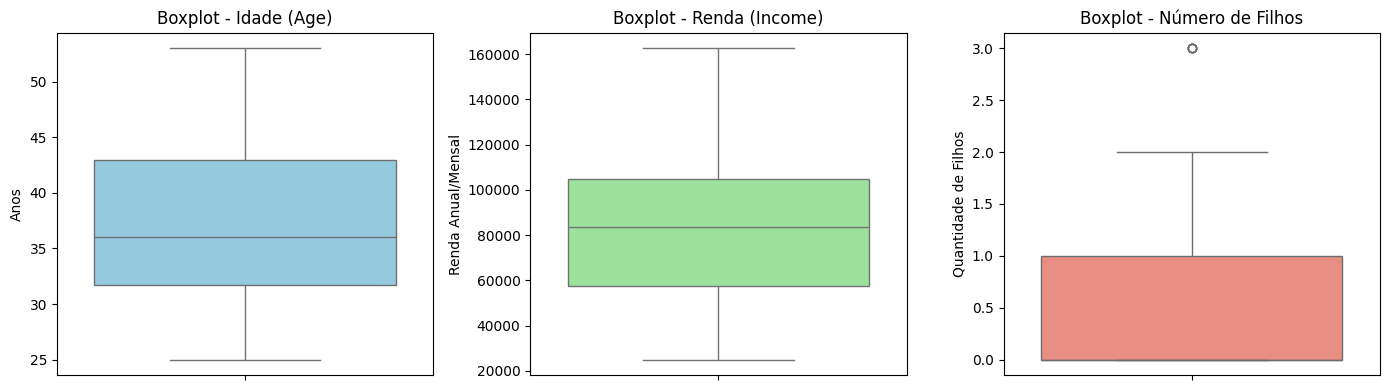

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Gerar gráficos de Boxplot para identificar visualmente a presença de outliers
plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
sns.boxplot(y=df['Age'], color='skyblue')
plt.title('Boxplot - Idade (Age)')
plt.ylabel('Anos')

plt.subplot(1, 3, 2)
sns.boxplot(y=df['Income'], color='lightgreen')
plt.title('Boxplot - Renda (Income)')
plt.ylabel('Renda Anual/Mensal')

plt.subplot(1, 3, 3)
sns.boxplot(y=df['Number of Children'], color='salmon')
plt.title('Boxplot - Número de Filhos')
plt.ylabel('Quantidade de Filhos')

plt.tight_layout()
plt.show()

### Insights da Análise Univariada


Perfil de Idade: A base é composta por adultos jovens e de meia-idade (entre 25 e 53 anos), com uma média e mediana bastante alinhadas em torno dos 36/37 anos.

Perfil Financeiro: A renda média dos clientes é de aproximadamente 83.765,00, variando de 25.000,00 até R$ 162.500,00. A proximidade entre a média (83.765) e a mediana (83.750) indica uma distribuição bem equilibrada de renda.

 Estrutura Familiar: Mais de 50% dos clientes não possuem filhos. O número máximo de filhos é 3.

Ausência de Outliers Críticos: Não foram identificados outliers anômalos que exijam remoção ou tratamento corretivo severo nas variáveis numéricas.





### **B) Agora realize a análise univariada para as variaveis categóricas, plote gráficos para entender a distribuição das categorias e tente retirar insights de cada gráfico.**

/tmp/ipykernel_1644/2780355325.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.countplot(data=df, x='Gender', palette='Set2')
/tmp/ipykernel_1644/2780355325.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.countplot(data=df, x='Education', palette='Set2', order=df['Education'].value_counts().index)
/tmp/ipykernel_1644/2780355325.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax3 = sns.countplot(data=df, x='Marital Status', palette='Set2')
/tmp/ipykernel_1644/2780355325.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is depre

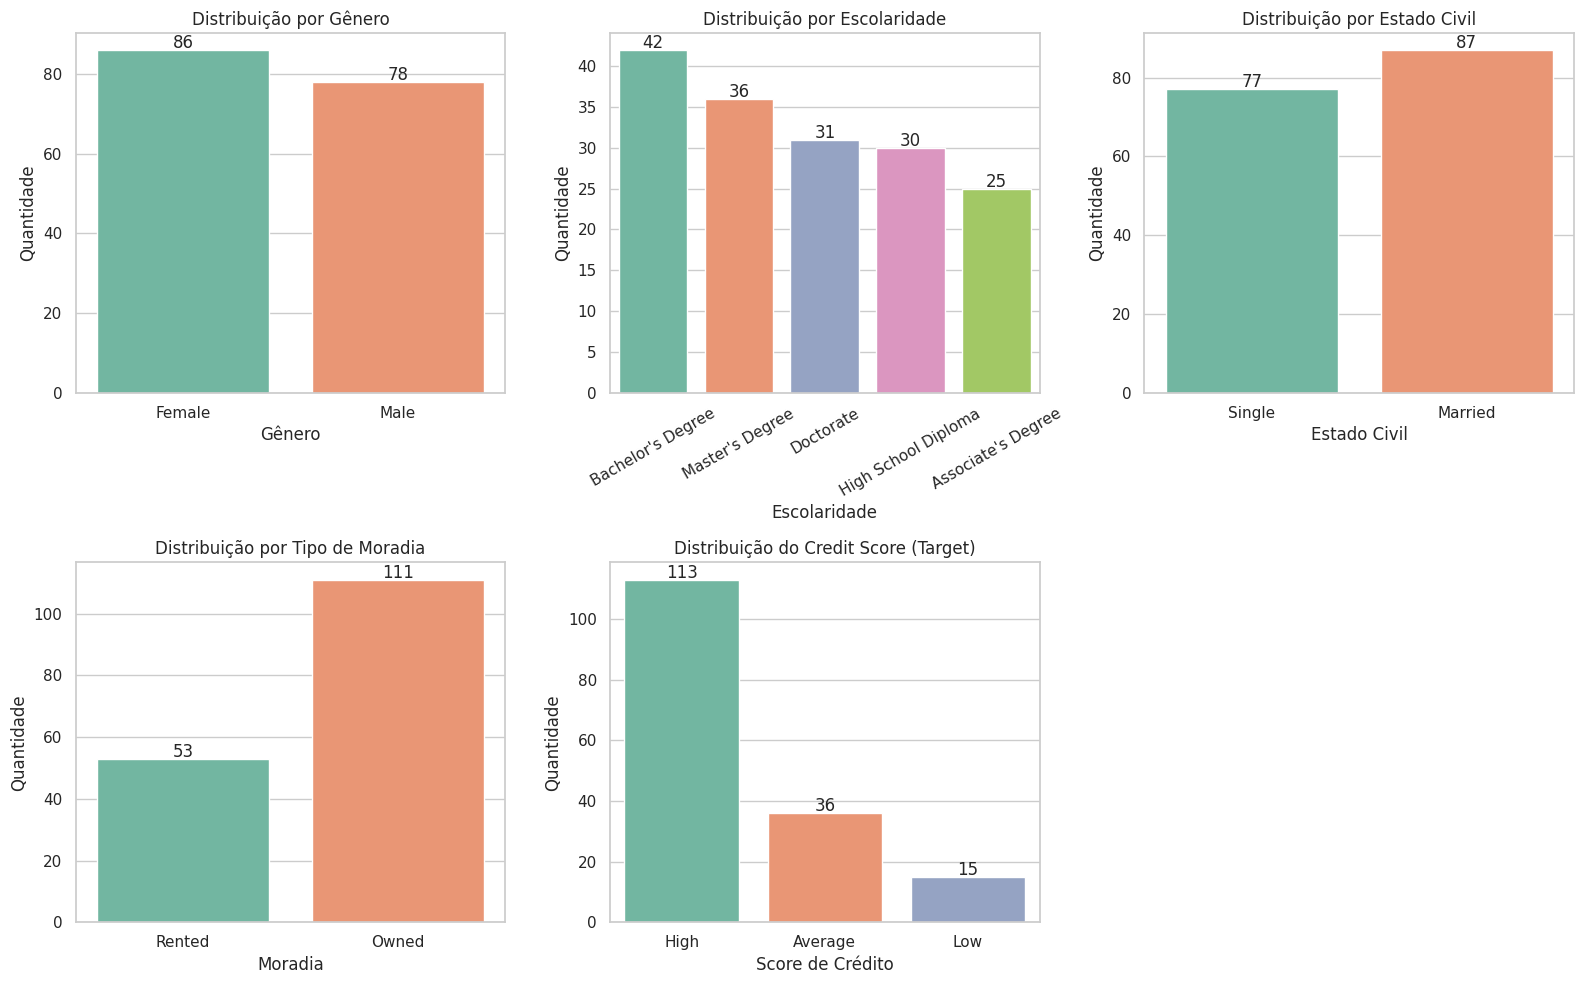

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo visual dos gráficos
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 10))

# 1. Gráfico de Gênero
plt.subplot(2, 3, 1)
ax1 = sns.countplot(data=df, x='Gender', palette='Set2')
plt.title('Distribuição por Gênero')
plt.xlabel('Gênero')
plt.ylabel('Quantidade')
for p in ax1.patches:
    ax1.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# 2. Gráfico de Escolaridade
plt.subplot(2, 3, 2)
ax2 = sns.countplot(data=df, x='Education', palette='Set2', order=df['Education'].value_counts().index)
plt.title('Distribuição por Escolaridade')
plt.xlabel('Escolaridade')
plt.ylabel('Quantidade')
plt.xticks(rotation=30)
for p in ax2.patches:
    ax2.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# 3. Gráfico de Estado Civil
plt.subplot(2, 3, 3)
ax3 = sns.countplot(data=df, x='Marital Status', palette='Set2')
plt.title('Distribuição por Estado Civil')
plt.xlabel('Estado Civil')
plt.ylabel('Quantidade')
for p in ax3.patches:
    ax3.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# 4. Gráfico de Tipo de Moradia
plt.subplot(2, 3, 4)
ax4 = sns.countplot(data=df, x='Home Ownership', palette='Set2')
plt.title('Distribuição por Tipo de Moradia')
plt.xlabel('Moradia')
plt.ylabel('Quantidade')
for p in ax4.patches:
    ax4.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# 5. Gráfico do Credit Score (Variável Target)
plt.subplot(2, 3, 5)
ax5 = sns.countplot(data=df, x='Credit Score', palette='Set2', order=['High', 'Average', 'Low'])
plt.title('Distribuição do Credit Score (Target)')
plt.xlabel('Score de Crédito')
plt.ylabel('Quantidade')
for p in ax5.patches:
    ax5.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

### Insights dos Gráficos

Equilíbrio de Gênero: A amostra apresenta excelente equilíbrio entre mulheres (86) e homens (78).

Nível de Escolaridade Elevado: A maior parte dos clientes possui ensino superior ou pós-graduação (Bachelor's Degree: 42, Master's Degree: 36, Doctorate: 31).

Estado Civil: Há um equilíbrio suave entre clientes casados (Married: 87) e solteiros (Single: 77).

Patrimônio/Moradia: A maioria expressiva dos clientes possui casa própria (Owned: 111), enquanto uma minoria mora em imóvel alugado (Rented: 53).

Desequilíbrio na Variável Alvo (Credit Score): A classe de score alto (High: 113) domina a base. As classes de score médio (Average: 36) e baixo (Low: 15) são minoritárias.

### C) Você encontrou alguma coluna com outliers?
Se sim realize o tratamento desses casos.

In [11]:
# Verificação final e justificativa de outliers
print("--- Análise de Tratamento de Outliers ---")
print("Após inspecionar os boxplots das variáveis numéricas (Age, Income e Number of Children):")
print("- Não foram encontrados outliers anômalos ou erros de digitação.")
print("- O valor máximo de 3 filhos (Number of Children) é uma informação real plausível, não devendo ser removido.")
print("- Portanto, nenhuma exclusão ou transformação de outliers é necessária nesta etapa.")

--- Análise de Tratamento de Outliers ---
Após inspecionar os boxplots das variáveis numéricas (Age, Income e Number of Children):
- Não foram encontrados outliers anômalos ou erros de digitação.
- O valor máximo de 3 filhos (Number of Children) é uma informação real plausível, não devendo ser removido.
- Portanto, nenhuma exclusão ou transformação de outliers é necessária nesta etapa.


### D) Realize a análise Bivariada.
Tente responder as seguintes perguntas com gráficos seguidos de insights:

/tmp/ipykernel_1644/1346026739.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Marital Status', y='Age', palette='Set2')


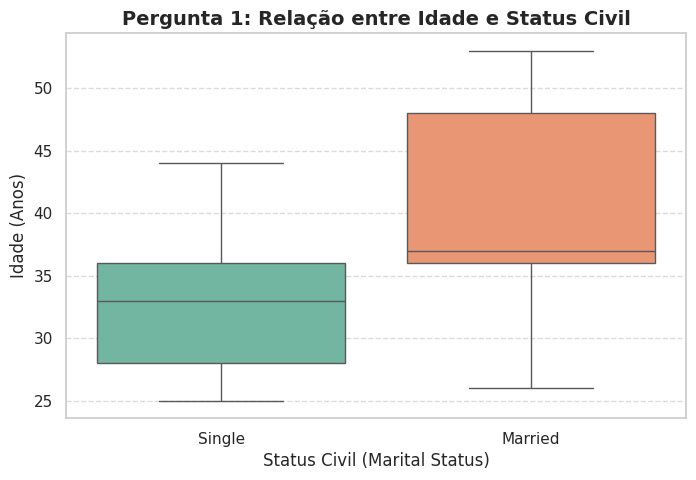

,count,mean,std,min,25%,50%,75%,max
Marital Status,,,,,,,,
Married,87.00,40.39,7.42,26.00,36.00,37.00,48.00,53.00
Single,77.00,33.58,6.02,25.00,28.00,33.00,36.00,44.00


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Gráfico Bivariado: Idade x Status Civil
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Marital Status', y='Age', palette='Set2')

plt.title('Pergunta 1: Relação entre Idade e Status Civil', fontsize=14, fontweight='bold')
plt.xlabel('Status Civil (Marital Status)', fontsize=12)
plt.ylabel('Idade (Anos)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

# 2. Resumo estatístico de suporte
display(df.groupby('Marital Status')['Age'].describe())

*   Existe relação entre a idade e o status civil?

Sim, existe uma relação direta entre a idade e o estado civil.
Os clientes solteiros (Single) são, em média, mais jovens, concentrando-se entre 28 e 36 anos (com mediana de 33 anos e idade máxima de 44 anos).
Já os clientes casados (Married) pertencem a uma faixa etária mais elevada, com grande parte do grupo estando entre 36 e 48 anos (com mediana de 37 anos e chegando até 53 anos).

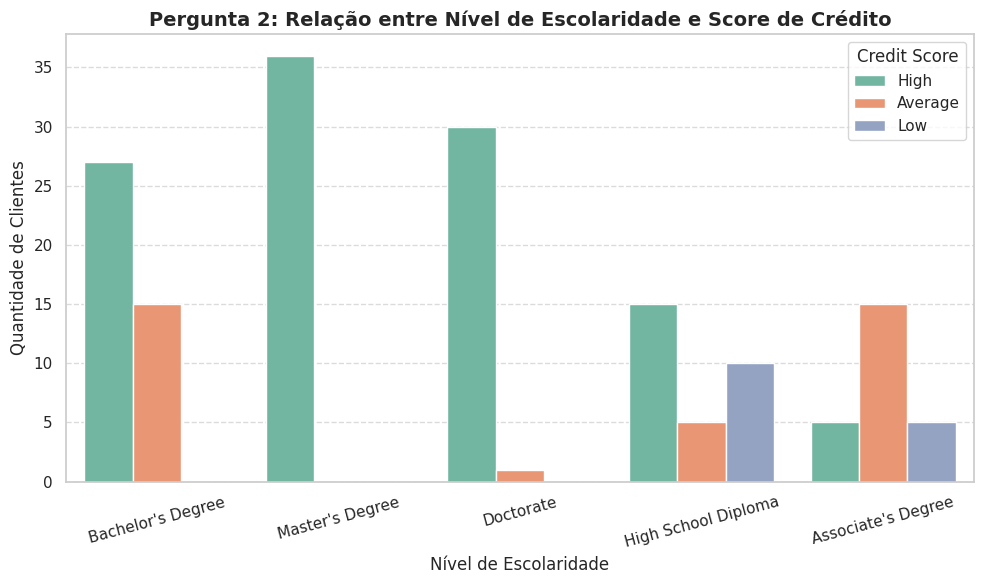

Credit Score,Average,High,Low
Education,,,
Associate's Degree,60.00,20.00,20.00
Bachelor's Degree,35.71,64.29,0.00
Doctorate,3.23,96.77,0.00
High School Diploma,16.67,50.00,33.33
Master's Degree,0.00,100.00,0.00


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Gráfico Bivariado: Escolaridade x Score de Crédito
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df,
    x='Education',
    hue='Credit Score',
    hue_order=['High', 'Average', 'Low'],
    palette='Set2'
)

plt.title('Pergunta 2: Relação entre Nível de Escolaridade e Score de Crédito', fontsize=14, fontweight='bold')
plt.xlabel('Nível de Escolaridade', fontsize=12)
plt.ylabel('Quantidade de Clientes', fontsize=12)
plt.xticks(rotation=15)
plt.legend(title='Credit Score')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# 2. Tabela de cruzamento percentual para dar suporte ao insight
tabela_cruzada = pd.crosstab(df['Education'], df['Credit Score'], normalize='index') * 100
display(tabela_cruzada.round(2))

*   Qual a relação entre o score de crédito e o nível de escolaridade?

Existe uma forte relação positiva entre o nível de escolaridade e o score de crédito do cliente.

Clientes com pós-graduação (Mestrado e Doutorado) possuem quase 100% de prevalência de Score Alto (High), não apresentando nenhum caso de score baixo.

Clientes com Bacharelado mantêm uma distribuição predominantemente positiva (64,3% de Score Alto e 35,7% de Score Médio).

Por outro lado, os scores baixos (Low) concentram-se fortemente em clientes com níveis de escolaridade de Ensino Médio (High School) e Grau Técnico (Associate's Degree).

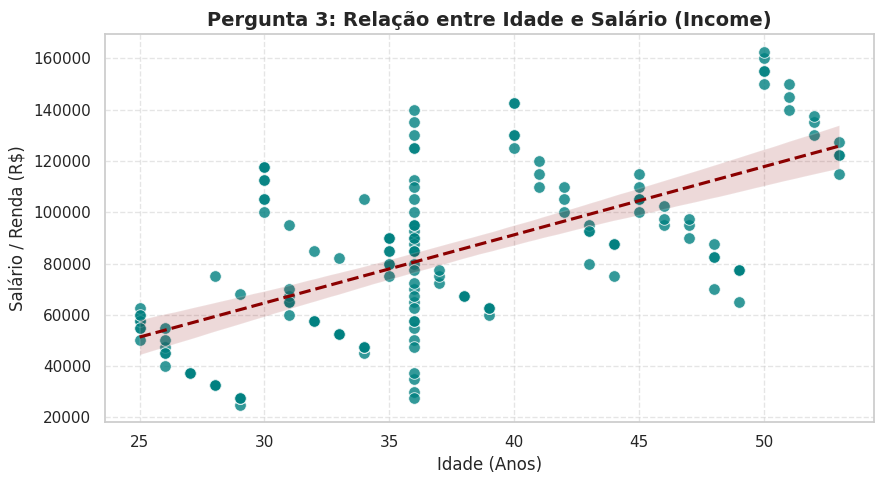

Coeficiente de Correlação de Pearson entre Idade e Salário: 0.62


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Gráfico de Dispersão: Idade x Salário
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='Age', y='Income', color='teal', s=70, alpha=0.8)

# 2. Linha de tendência para visualizar a inclinação
sns.regplot(data=df, x='Age', y='Income', scatter=False, color='darkred', line_kws={'linestyle':'--'})

plt.title('Pergunta 3: Relação entre Idade e Salário (Income)', fontsize=14, fontweight='bold')
plt.xlabel('Idade (Anos)', fontsize=12)
plt.ylabel('Salário / Renda (R$)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 3. Exibir o valor da correlação matemática
correlacao = df['Age'].corr(df['Income'])
print(f"Coeficiente de Correlação de Pearson entre Idade e Salário: {correlacao:.2f}")

*  O salário parece influenciar na idade?

Sim, existe uma clara relação positiva e direta entre a idade e o salário dos clientes (correlação de +0,62).

De modo geral, clientes mais velhos tendem a ter salários mais elevados.

Clientes na faixa dos 25 aos 30 anos possuem rendas predominantemente entre  25.000 e 60.000 reais.

Já os clientes acima de 45 a 50 anos concentram-se em faixas salariais superiores, ultrapassando 120.000 reais e chegando até 162.500 reais.

Justificativa de Negócio: Esse padrão é esperado no mercado financeiro, pois profissionais com maior tempo de carreira e maturidade profissional tendem a acumular cargos mais altos e maiores rendimentos.


/tmp/ipykernel_1644/1312022252.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


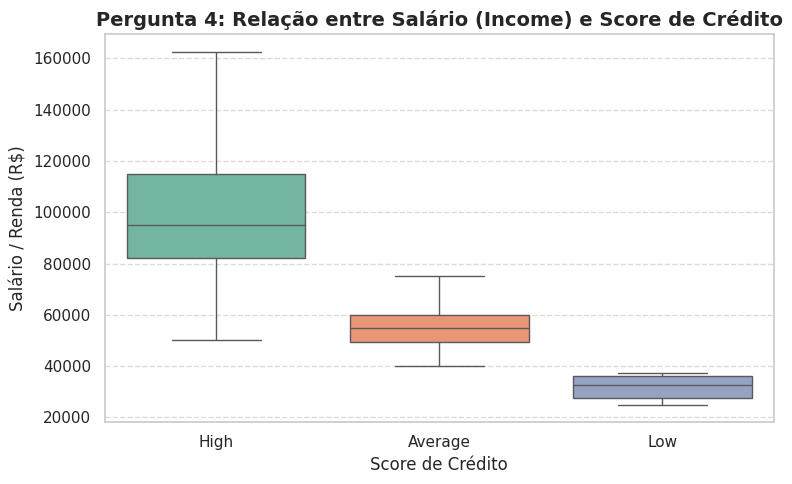

,count,mean,std,min,25%,50%,75%,max
Credit Score,,,,,,,,
Average,36.00,55500.00,7923.74,40000.00,49375.00,55000.00,60000.00,75000.00
High,113.00,99641.59,25322.16,50000.00,82000.00,95000.00,115000.00,162500.00
Low,15.00,32000.00,4350.70,25000.00,27500.00,32500.00,36250.00,37500.00


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Gráfico Bivariado: Salário x Score de Crédito
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x='Credit Score',
    y='Income',
    order=['High', 'Average', 'Low'],
    palette='Set2'
)

plt.title('Pergunta 4: Relação entre Salário (Income) e Score de Crédito', fontsize=14, fontweight='bold')
plt.xlabel('Score de Crédito', fontsize=12)
plt.ylabel('Salário / Renda (R$)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# 2. Resumo estatístico de suporte
display(df.groupby('Credit Score')['Income'].describe().round(2))

* O salário parece influenciar no Score de Crédito?

Sim, o salário é um determinante crucial para o Score de Crédito do cliente.

Existe uma nítida separação em patamares de renda para cada categoria de score:

Clientes com Score Baixo (Low) possuem as rendas mais baixas da base, variando entre R$ 25.000,00 e R$ 37.500,00 (mediana de R$ 32.500,00).

Clientes com Score Médio (Average) ocupam a faixa intermediária de salário, entre R$ 40.000,00 e R$ 75.000,00 (mediana de R$ 55.000,00).

Clientes com Score Alto (High) detêm as maiores rendas, alcançando mediana de R$ 95.000,00 e valores de até R$ 162.500,00.

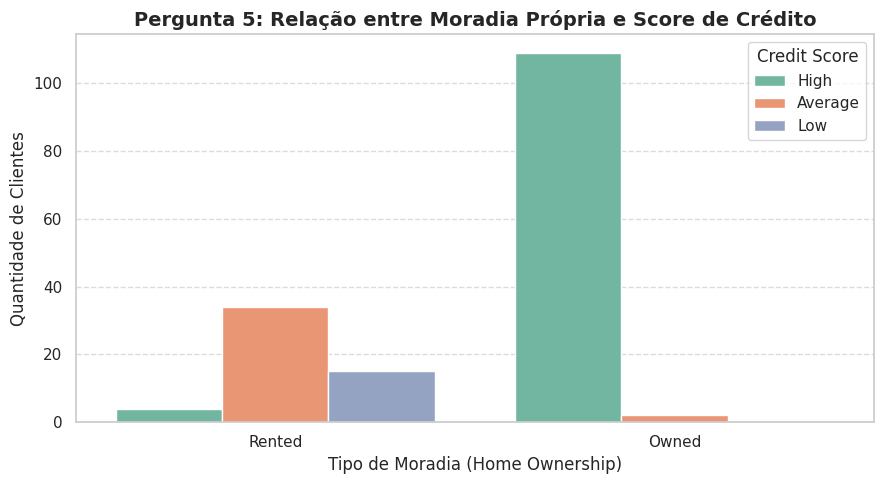

Credit Score,High,Average,Low
Home Ownership,,,
Owned,98.20,1.80,0.00
Rented,7.55,64.15,28.30


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Gráfico Bivariado: Tipo de Moradia x Score de Crédito
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x='Home Ownership',
    hue='Credit Score',
    hue_order=['High', 'Average', 'Low'],
    palette='Set2'
)

plt.title('Pergunta 5: Relação entre Moradia Própria e Score de Crédito', fontsize=14, fontweight='bold')
plt.xlabel('Tipo de Moradia (Home Ownership)', fontsize=12)
plt.ylabel('Quantidade de Clientes', fontsize=12)
plt.legend(title='Credit Score')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# 2. Tabela cruzada em porcentagem por linha
tabela_moradia = pd.crosstab(df['Home Ownership'], df['Credit Score'], normalize='index') * 100
display(tabela_moradia[['High', 'Average', 'Low']].round(2))

* Clientes com casa própria tendem a ter um score mais alto?

Sim, existe uma associação forte e clara entre possuir casa própria e apresentar Score de Crédito Alto (High).

Dos 111 clientes que possuem casa própria (Owned), 98,20% (109 clientes) estão na categoria de Score Alto, e nenhum cliente com casa própria apresenta Score Baixo.

Por outro lado, entre os clientes que moram em imóvel alugado (Rented), a grande maioria concentra-se nos níveis Médio (64,15%) e Baixo (28,30%).

Conclusão de Negócio: A posse de imóvel funciona como um importante indicador de patrimônio e estabilidade financeira para a concessão de crédito.

(Minha Pergunta 1): Existe diferença na distribuição do Score de Crédito entre os gêneros masculino e feminino?

Credit Score,High,Average,Low
Gender,,,
Female,65.12,17.44,17.44
Male,73.08,26.92,0.00


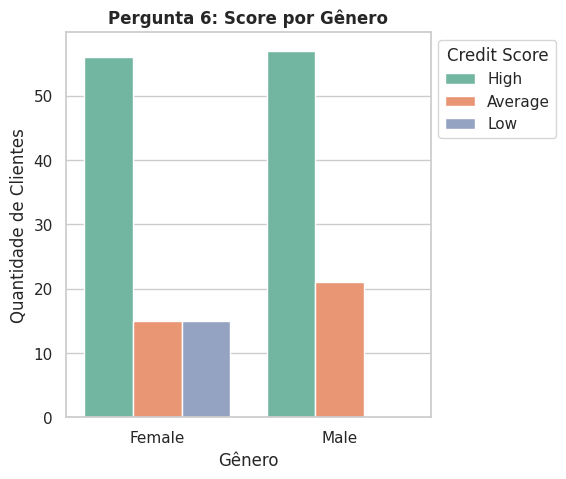

In [17]:
plt.figure(figsize=(16, 5))

# 1. Pergunta 6: Score por Gênero
ax1 = plt.subplot(1, 3, 1)
sns.countplot(data=df, x='Gender', hue='Credit Score', hue_order=['High', 'Average', 'Low'], palette='Set2')
plt.title('Pergunta 6: Score por Gênero', fontsize=12, fontweight='bold')
plt.xlabel('Gênero')
plt.ylabel('Quantidade de Clientes')

sns.move_legend(ax1, "upper left", bbox_to_anchor=(1, 1)) # Move a legenda para fora

# 2. Tabela cruzada em porcentagem por linha
tabela_genero = pd.crosstab(df['Gender'], df['Credit Score'], normalize='index') * 100
display(tabela_genero[['High', 'Average', 'Low']].round(2))

Insight (Gênero x Score): Notou-se que na amostra analisada os homens apresentam maior proporção de Score Alto (73%) e nenhum registro de Score Baixo, enquanto as mulheres concentram a totalidade dos registros com Score Baixo (17,4%).

(Minha Pergunta 2): Como o estado civil (casado vs. solteiro) impacta a classificação do Score de Crédito?

Credit Score,High,Average,Low
Marital Status,,,
Married,97.70,2.30,0.00
Single,36.36,44.16,19.48


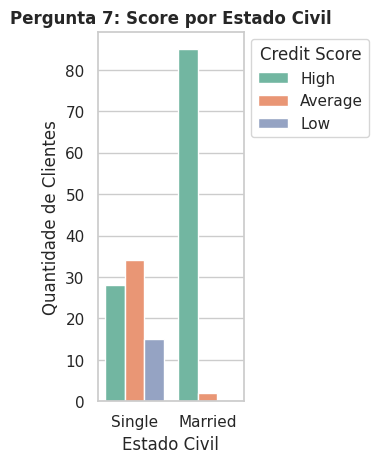

In [18]:
# 2. Pergunta 7: Score por Estado Civil
ax2 = plt.subplot(1, 3, 2)
sns.countplot(data=df, x='Marital Status', hue='Credit Score', hue_order=['High', 'Average', 'Low'], palette='Set2')
plt.title('Pergunta 7: Score por Estado Civil', fontsize=12, fontweight='bold')
plt.xlabel('Estado Civil')
plt.ylabel('Quantidade de Clientes')

sns.move_legend(ax2, "upper left", bbox_to_anchor=(1, 1)) # Move a legenda para fora

# 2. Tabela cruzada em porcentagem por linha
tabela_status = pd.crosstab(df['Marital Status'], df['Credit Score'], normalize='index') * 100
display(tabela_status[['High', 'Average', 'Low']].round(2))

Insight (Estado Civil x Score): Clientes casados possuem uma estabilidade de crédito expressivamente maior, onde 97,7% da categoria possui Score Alto. Já os solteiros concentram as categorias de Score Médio e Baixo.

(Minha Pergunta 3): "Existe relação entre a faixa etária (idade) do cliente e o seu Score de Crédito?

/tmp/ipykernel_1644/352763023.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Credit Score', y='Age', order=['High', 'Average', 'Low'], palette='Set2')


Text(0, 0.5, 'Idade (Anos)')

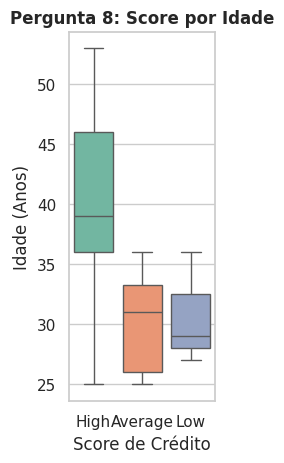

In [19]:
# 3. Pergunta 8: Score por Idade
plt.subplot(1, 3, 3)
sns.boxplot(data=df, x='Credit Score', y='Age', order=['High', 'Average', 'Low'], palette='Set2')
plt.title('Pergunta 8: Score por Idade', fontsize=12, fontweight='bold')
plt.xlabel('Score de Crédito')
plt.ylabel('Idade (Anos)')




Insight (Idade x Score): Clientes com Score Alto possuem faixa etária mais avançada (mediana de 39 anos), ao passo que clientes com Score Médio e Baixo são mais jovens (mediana de 30-31 anos).

### # Etapa 3: Relize os passos que vimos no módulo 17, de Correlação, Balanceamento, atributos categóricos e divisão base treino e teste.

**A) Vamos começar pela análise de correlação, plote da forma que achar melhor a análise de correlação, seja pela tabela ou pelo gráfico da matriz.**

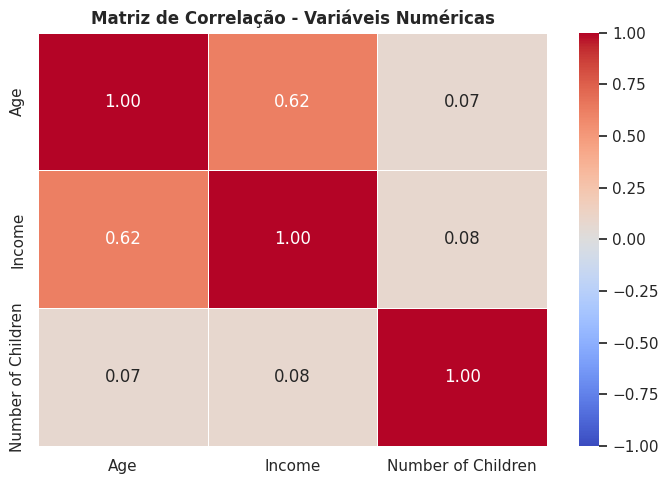

,Age,Income,Number of Children
Age,1.00,0.62,0.07
Income,0.62,1.00,0.08
Number of Children,0.07,0.08,1.00


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Selecionar apenas as colunas numéricas
colunas_numericas = ['Age', 'Income', 'Number of Children']
matriz_correlacao = df[colunas_numericas].corr()

# 2. Gerar o gráfico de Mapa de Calor (Heatmap)
plt.figure(figsize=(7, 5))
sns.heatmap(matriz_correlacao, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)

plt.title('Matriz de Correlação - Variáveis Numéricas', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 3. Exibir a tabela com as correlações
display(matriz_correlacao.round(2))

### B) Você encontrou variáveis que tem uma média ou alta correlação? Se sim, quais? Te parece fazer sentido essas variáveis terem alta correlação? Justifique.

Correlação Forte entre Idade e Salário: A matriz de correlação revelou uma relação linear positiva moderada a forte entre as variáveis Age (Idade) e Income (Salário), com um coeficiente de $r = 0,62$.Interpretação de Negócio: Esse resultado confirma que, à medida que a idade do cliente aumenta, há uma tendência proporcional de elevação da sua renda mensal/anual. No contexto bancário, esse comportamento é perfeitamente condizente com a progressão de carreira, maior tempo de mercado e acúmulo de patrimônio ao longo dos anos.Baixa Correlação do Número de Filhos: Por outro lado, a variável Number of Children apresentou correlações próximas de zero tanto com a idade ($0,07$) quanto com a renda ($0,08$), indicando que o número de dependentes não possui relação linear direta com o patamar financeiro ou etário da amostra.



### C) Temos muitos atributos categóricos nessa base, não? Vamos realizar a o tratamento desses atributos utilizando Label Encoder ou one hot. Após, exclua as colunas categóricas.

In [21]:
import pandas as pd

# 1. Mapeamento Ordinal (Label Encoding) para colunas com ordem hierárquica clara
mapeamento_educacao = {
    'High School Diploma': 0,
    'Associate\'s Degree': 1,
    'Bachelor\'s Degree': 2,
    'Master\'s Degree': 3,
    'Doctorate': 4
}

mapeamento_score = {
    'Low': 0,
    'Average': 1,
    'High': 2
}

# Aplicando os mapeamentos
df['Education_encoded'] = df['Education'].map(mapeamento_educacao)
df['Credit_Score_encoded'] = df['Credit Score'].map(mapeamento_score)

# 2. One-Hot Encoding para variáveis categóricas sem ordem (Gênero, Estado Civil, Moradia)
df_encoded = pd.get_dummies(df, columns=['Gender', 'Marital Status', 'Home Ownership'], drop_first=True)

# 3. Excluir as colunas categóricas originais de texto ('Education' e 'Credit Score')
df_encoded = df_encoded.drop(columns=['Education', 'Credit Score'])

# 4. Exibir as primeiras linhas do novo DataFrame 100% numérico
display(df_encoded.head())

,Age,Income,Number of Children,Education_encoded,Credit_Score_encoded,Gender_Male,Marital Status_Single,Home Ownership_Rented
0,25.00,50000.00,0,2,2,False,True,True
1,30.00,100000.00,2,3,2,True,False,False
2,35.00,75000.00,1,4,2,False,False,False
3,40.00,125000.00,0,0,2,True,True,False
4,45.00,100000.00,3,2,2,False,False,False


### Justificativa

Se Gender_Male for 0 (False), o modelo já sabe automaticamente que a pessoa é Female. Criar uma coluna Gender_Female seria pura informação duplicada.

Na estatística e no aprendizado de máquina, essa duplicidade é chamada de Multicolinearidade Perfeita (ou a "Armadilha das Variáveis Dummy"). Remover uma das colunas reduz o tamanho do dataset, evita redundância e impede que o modelo fique confuso ou viciado durante o treinamento.

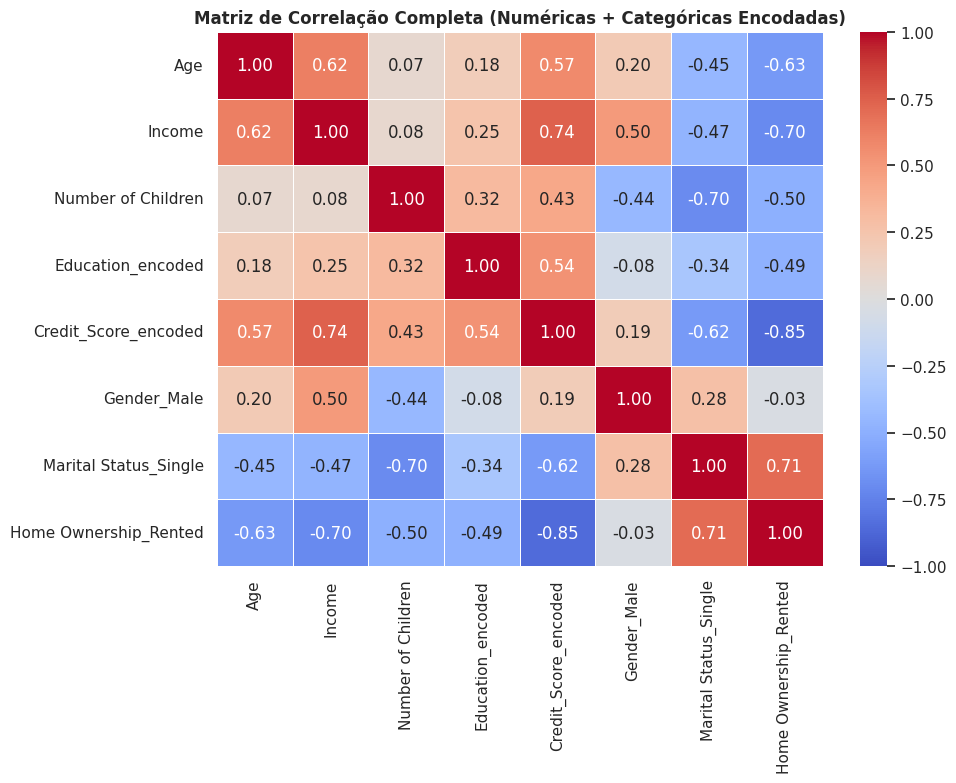

--- Correlação com a Variável Alvo (Credit_Score_encoded) ---


,Credit_Score_encoded
Credit_Score_encoded,1.00
Income,0.74
Age,0.57
Education_encoded,0.54
Number of Children,0.43
Gender_Male,0.19
Marital Status_Single,-0.62
Home Ownership_Rented,-0.85


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcular a matriz de correlação de TODAS as colunas numéricas e encodadas
matriz_completa = df_encoded.corr()

# 2. Gerar o gráfico Heatmap completo
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_completa, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)

plt.title('Matriz de Correlação Completa (Numéricas + Categóricas Encodadas)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 3. Exibir apenas a correlação de todas as variáveis em relação ao Credit Score
print("--- Correlação com a Variável Alvo (Credit_Score_encoded) ---")
display(matriz_completa['Credit_Score_encoded'].sort_values(ascending=False).round(2))

Análise da Matriz de Correlação Completa:

Variáveis de Maior Correlação Positiva: As colunas com forte associação positiva ao Credit_Score_encoded foram a Renda (Income, $r = 0,74$) e a Idade (Age, $r = 0,57$). Isso confirma que clientes com maior patrimônio financeiro e faixa etária mais madura concentram as melhores pontuações de crédito.Variáveis de Correlação Negativa Expressiva: Destacam-se as variáveis encodadas Home Ownership_Rented ($r = -0,85$) e Marital Status_Single ($r = -0,62$).Significado Prático: O sinal negativo indica que a presença dessas características (residir em imóvel alugado ou ser solteiro) está fortemente associada a patamares inferiores de score de crédito na base analisada.

### E) Faça a separação da base em treino e teste e verifique utilizando shape:

In [23]:
from sklearn.model_selection import train_test_split

# 1. Separar as variáveis preditoras (X) da variável alvo (y)
X = df_encoded.drop(columns=['Credit_Score_encoded'])
y = df_encoded['Credit_Score_encoded']

# 2. Dividir em Treino (80%) e Teste (20%) com estratificação
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Tamanho total da base: {len(df_encoded)} linhas")
print(f"Tamanho do conjunto de Treino (X_train): {len(X_train)} linhas")
print(f"Tamanho do conjunto de Teste (X_test): {len(X_test)} linhas")

Tamanho total da base: 164 linhas
Tamanho do conjunto de Treino (X_train): 131 linhas
Tamanho do conjunto de Teste (X_test): 33 linhas


Proporção da Divisão: O dataset de 164 registros foi dividido em 80% para treino (131 amostras) e 20% para teste (33 amostras), utilizando o método stratify=y para preservar o equilíbrio de proporções da variável alvo Credit Score.

Justificativa de Negócio: Testar um algoritmo com os mesmos dados utilizados no seu treinamento gera o problema de Overfitting (sobreajuste), onde o modelo decora os padrões da base histórica e perde a capacidade de generalização. A validação em dados inéditos de teste assegura a confiabilidade preditiva em cenários reais de concessão de crédito.

### F) É hora de verificar se nossa coluna de Score de crédito está balanceada, verifique através de um gráfico e traga sua opinião acerca do balanceamento.

/tmp/ipykernel_1644/2585419316.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=y_train_rotulado, order=['High', 'Average', 'Low'], palette='Set2')


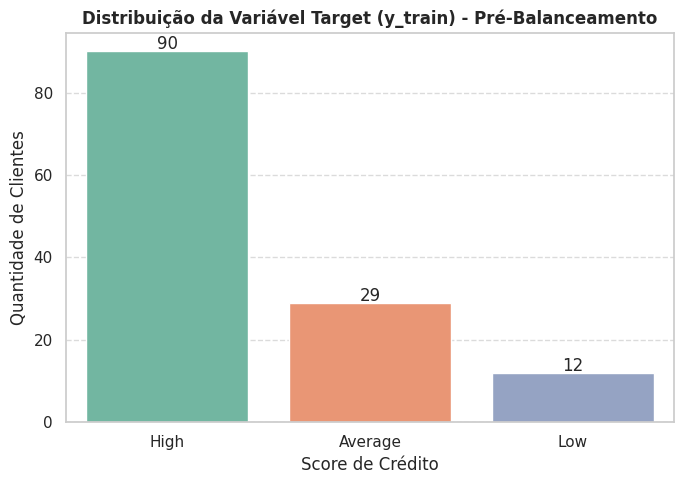

--- Contagem Absoluta no Treino ---
Credit_Score_encoded
High       90
Average    29
Low        12
Name: count, dtype: int64

--- Porcentagem Relativa no Treino (%) ---
Credit_Score_encoded
High      68.70
Average   22.14
Low        9.16
Name: proportion, dtype: float64


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Mapeamento reverso para exibir os nomes originais no gráfico ('Low', 'Average', 'High')
nomes_classes = {0: 'Low', 1: 'Average', 2: 'High'}
y_train_rotulado = y_train.map(nomes_classes)

# 2. Criar o gráfico de barras da distribuição no treino
plt.figure(figsize=(7, 5))
ax = sns.countplot(x=y_train_rotulado, order=['High', 'Average', 'Low'], palette='Set2')

plt.title('Distribuição da Variável Target (y_train) - Pré-Balanceamento', fontsize=12, fontweight='bold')
plt.xlabel('Score de Crédito')
plt.ylabel('Quantidade de Clientes')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adicionar os valores numéricos em cima de cada barra
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

# 3. Exibir a contagem e porcentagem exatas no terminal
print("--- Contagem Absoluta no Treino ---")
print(y_train_rotulado.value_counts())
print("\n--- Porcentagem Relativa no Treino (%) ---")
print((y_train_rotulado.value_counts(normalize=True) * 100).round(2))

### Análise do Balanceamento da Variável Target (y_train):

Distribuição Observada: A base de treino apresenta um forte desequilíbrio de classes: a categoria High possui 90 registros (68,70%), a categoria Average conta com 29 registros (22,14%) e a categoria Low contém apenas 12 registros (9,16%).

Diagnóstico e Risco: A base classifica-se como desbalanceada. Treinar um modelo supervisionado nesta condição traz o risco de viés em direção à classe majoritária (High), reduzindo drasticamente a sensibilidade do algoritmo para detectar clientes de score baixo (Low).

Recomendação: É altamente necessária a aplicação de uma técnica de reamostragem/balanceamento (como o SMOTE) antes da etapa de modelagem preditiva.

### G) Vamos realizar o balancecamento dos dados da coluna de credit score.
Se lembre que realizazmos apenas para a base de treino.

In [25]:
from imblearn.over_sampling import SMOTE
import pandas as pd

# 1. Aplicar o SMOTE apenas na base de Treino
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

# Mapeamento para exibição clara
nomes_classes = {0: 'Low', 1: 'Average', 2: 'High'}
y_train_bal_rotulado = pd.Series(y_train_bal).map(nomes_classes)

# 2. Exibir a nova contagem das classes no Treino DEPOIS do SMOTE
print("--- Distribuição DEPOIS do Balanceamento SMOTE (y_train_bal) ---")
print(y_train_bal_rotulado.value_counts())

--- Distribuição DEPOIS do Balanceamento SMOTE (y_train_bal) ---
Credit_Score_encoded
Average    90
High       90
Low        90
Name: count, dtype: int64


Aplicação do Balanceamento SMOTE:

Resultado da Reamostragem: Após a aplicação da técnica SMOTE (Synthetic Minority Over-sampling Technique) no conjunto de treino, as classes minoritárias Average e Low foram sintetizadas para equiparar-se à classe majoritária, resultando em uma distribuição perfeitamente equilibrada de 90 registros para cada categoria (High, Average e Low).

Justificativa Metodológica: A técnica foi aplicada exclusivamente na base de Treino (X_train). A base de Teste (X_test) foi preservada em sua distribuição original para evitar vazamento de dados (data leakage) e garantir que a avaliação final do modelo meça seu desempenho real perante a distribuição genuína de clientes no mercado.